# Boosting Techniques — Assignment Solutions
---

## Part A: Theoretical Questions (Q1 – Q13) [cite: 25]


### 1. What is Boosting in Machine Learning?
**Answer:**  
**Boosting** is an ensemble meta-algorithm that converts a sequence of weak learners (models slightly better than random guessing, typically shallow decision trees) into a strong learner [cite: 25]. Unlike Bagging where models are trained in parallel, Boosting trains models **sequentially**, where each new model explicitly focuses on correcting the errors, residuals, or misclassified samples of the previous models.


### 2. How does Boosting differ from Bagging?
**Answer:**  
- **Training Architecture:** Bagging trains base models **in parallel** and independently; Boosting trains base models **sequentially** [cite: 25].  
- **Data Weighting:** Bagging uses uniform random bootstrap sampling with replacement; Boosting re-weights training instances or fits subsequent models on the pseudo-residuals of prior models.  
- **Primary Objective:** Bagging primarily reduces **variance** (prevents overfitting); Boosting primarily reduces **bias** (improves predictive accuracy).


### 3. What is the key idea behind AdaBoost?
**Answer:**  
**AdaBoost (Adaptive Boosting)** maintains a weight distribution over the training dataset [cite: 25]. After each weak learner is trained, misclassified data points receive **higher weights**, while correctly classified points receive lower weights. Subsequent weak learners are forced to focus on these hard-to-classify instances. Finally, models are combined via a weighted majority vote based on their individual classification accuracies.


### 4. Explain the working of AdaBoost with an example.
**Answer:**  
**Example (Binary Classification of Email Spam):**  
1. **Initialization:** Assign equal weight $w_i = 1/N$ to all $N$ emails.  
2. **Iteration 1:** Train a decision stump (shallow tree). Suppose it misclassifies 10 emails.  
3. **Weight Update:** Increase weights of those 10 misclassified emails and compute the stump's voting weight (alpha) based on its error rate.  
4. **Iteration 2:** Train the next decision stump on the re-weighted dataset so it pays special attention to the previously failed emails.  
5. **Aggregation:** Combine all stumps into a final ensemble where predictions are weighted by each stump's reliability.


### 5. What is Gradient Boosting, and how is it different from AdaBoost?
**Answer:**  
**Gradient Boosting** generalizes boosting by framing it as a numerical optimization problem in function space [cite: 25]. Instead of re-weighting data points like AdaBoost, Gradient Boosting trains each new sequential tree to predict the **pseudo-residuals** (negative gradients of the loss function) of the current ensemble's predictions.


### 6. What is the loss function in Gradient Boosting?
**Answer:**  
The loss function measures the discrepancy between predicted and actual values [cite: 25]. Common choices include:  
- **Regression:** Mean Squared Error (MSE), Mean Absolute Error (MAE), and Huber Loss.  
- **Classification:** Binary / Multiclass Cross-Entropy (Log-Loss).


### 7. How does XGBoost improve over traditional Gradient Boosting?
**Answer:**  
- **Regularization:** Adds $L_1$ (Lasso) and $L_2$ (Ridge) regularization penalties to the objective function to prevent overfitting [cite: 25].  
- **Second-Order Approximation:** Uses a second-order Taylor expansion of the loss function (incorporating both first gradients and second-order Hessians) for faster optimization.  
- **System Optimizations:** Parallelized tree construction (column block structure), cache-aware access, and efficient handling of sparse/missing values.


### 8. What is the difference between XGBoost and CatBoost?
**Answer:**  
- **Categorical Feature Handling:** CatBoost natively handles categorical features using advanced ordered target encoding without manual one-hot encoding; XGBoost requires numerical encoding (one-hot or ordinal) [cite: 25].  
- **Tree Growth:** CatBoost grows symmetric (balanced) trees to prevent overfitting; XGBoost uses level-wise tree growth.  
- **Speed & Regularization:** CatBoost is optimized out-of-the-box with minimal hyperparameter tuning required, whereas XGBoost offers extensive regularization and speed controls.


### 9. What are some real-world applications of Boosting techniques?
**Answer:**  
- **Finance & Banking:** Credit scoring, loan default prediction, and real-time fraud detection [cite: 25].  
- **E-Commerce:** Search ranking, recommendation systems, and customer churn prediction.  
- **Healthcare:** Disease risk prediction and diagnostic imaging analysis.  
- **Search Engines & Ads:** Click-through rate (CTR) prediction.


### 10. How does regularization help in XGBoost?
**Answer:**  
XGBoost incorporates $L_1$ ($lpha$) and $L_2$ ($\lambda$) regularization terms on leaf weights and tree complexity ($\gamma$) into its objective function [cite: 25]. This penalizes overly complex models, shrinks leaf weights, and smooths final predictions, substantially reducing overfitting.


### 11. What are some hyperparameters to tune in Gradient Boosting models?
**Answer:**  
- `n_estimators`: Number of sequential trees [cite: 25].  
- `learning_rate` ($\eta$): Shrinkage factor controlling each tree's contribution.  
- `max_depth`: Maximum depth of individual trees.  
- `subsample`: Fraction of samples used for fitting each tree (stochastic gradient boosting).  
- `colsample_bytree`: Fraction of features sampled per tree.


### 12. What is the concept of Feature Importance in Boosting?
**Answer:**  
Feature importance measures how useful or impactful each feature was in constructing the boosted trees [cite: 25]. Common measures include:  
- **Gain:** Average gain in loss reduction brought by a feature across all splits.  
- **Weight (Frequency):** Total number of times a feature is used to split data across all trees.  
- **Coverage:** Number of training samples affected by splits on that feature.


### 13. Why is CatBoost efficient for categorical data?
**Answer:**  
CatBoost uses **Ordered Target Statistics**, an innovative permutation-driven encoding scheme that converts categorical string labels into numerical values on-the-fly while preventing **target leakage** and overfitting, eliminating the need for tedious manual pre-encoding [cite: 25].


---

## Part B: Practical Questions (Q14 – Q30) [cite: 25]

Run the setup cell below first to import required libraries and datasets so every practical exercise executes cleanly in Google Colab.


In [4]:
!pip install -q catboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, load_iris, make_classification, make_regression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import AdaBoostClassifier, AdaBoostRegressor, GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, mean_absolute_error, mean_squared_error, r2_score,
    f1_score, log_loss, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve
)
from xgboost import XGBClassifier, XGBRegressor
from catboost import CatBoostClassifier

sns.set_theme(style="whitegrid")
print("Environment initialized successfully!")

Environment initialized successfully!


### 14. Train an AdaBoost Classifier on a sample dataset and print model accuracy. [cite: 25]


In [5]:
X_cls, y_cls = make_classification(n_samples=800, n_features=15, random_state=42)
X_tr, X_te, y_tr, y_te = train_test_split(X_cls, y_cls, test_size=0.2, random_state=42)

ada_clf = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=50, random_state=42)
ada_clf.fit(X_tr, y_tr)
print(f"Q14 - AdaBoost Classifier Accuracy: {accuracy_score(y_te, ada_clf.predict(X_te)):.4f}")


Q14 - AdaBoost Classifier Accuracy: 0.9125


### 15. Train an AdaBoost Regressor and evaluate performance using Mean Absolute Error (MAE). [cite: 25]


In [6]:
Xr, yr = make_regression(n_samples=800, n_features=10, noise=12.0, random_state=42)
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=42)

ada_reg = AdaBoostRegressor(n_estimators=50, random_state=42)
ada_reg.fit(Xr_tr, yr_tr)
print(f"Q15 - AdaBoost Regressor MAE: {mean_absolute_error(yr_te, ada_reg.predict(Xr_te)):.4f}")


Q15 - AdaBoost Regressor MAE: 86.7776


### 16. Train a Gradient Boosting Classifier on the Breast Cancer dataset and print feature importance. [cite: 25]


In [7]:
cancer = load_breast_cancer()
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(cancer.data, cancer.target, test_size=0.2, random_state=42)

gbc = GradientBoostingClassifier(n_estimators=100, random_state=42)
gbc.fit(Xc_tr, yc_tr)

feat_imp = pd.Series(gbc.feature_importances_, index=cancer.feature_names).sort_values(ascending=False)
print("Q16 - Top 10 Feature Importances (Gradient Boosting):")
print(feat_imp.head(10))


Q16 - Top 10 Feature Importances (Gradient Boosting):
mean concave points     0.450528
worst concave points    0.240103
worst radius            0.075589
worst perimeter         0.051408
worst texture           0.039886
worst area              0.038245
mean texture            0.027805
worst concavity         0.018725
concavity error         0.013068
area error              0.008415
dtype: float64


### 17. Train a Gradient Boosting Regressor and evaluate using R-Squared Score. [cite: 25]


In [8]:
gbr = GradientBoostingRegressor(n_estimators=100, random_state=42)
gbr.fit(Xr_tr, yr_tr)
print(f"Q17 - Gradient Boosting Regressor R² Score: {r2_score(yr_te, gbr.predict(Xr_te)):.4f}")


Q17 - Gradient Boosting Regressor R² Score: 0.8612


### 18. Train an XGBoost Classifier on a dataset and compare accuracy with Gradient Boosting. [cite: 25]


In [9]:
xgb_clf = XGBClassifier(n_estimators=100, random_state=42, use_label_encoder=False, eval_metric='logloss')
xgb_clf.fit(X_tr, y_tr)

gb_acc = accuracy_score(y_te, GradientBoostingClassifier(random_state=42).fit(X_tr, y_tr).predict(X_te))
xgb_acc = accuracy_score(y_te, xgb_clf.predict(X_te))

print(f"Q18 - Gradient Boosting Accuracy: {gb_acc:.4f}")
print(f"Q18 - XGBoost Accuracy:           {xgb_acc:.4f}")


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [11:33:52] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Q18 - Gradient Boosting Accuracy: 0.9437
Q18 - XGBoost Accuracy:           0.9187


### 19. Train a CatBoost Classifier and evaluate using F1-Score. [cite: 25]


In [10]:
cat_clf = CatBoostClassifier(iterations=100, verbose=0, random_state=42)
cat_clf.fit(X_tr, y_tr)
print(f"Q19 - CatBoost Classifier F1-Score: {f1_score(y_te, cat_clf.predict(X_te)):.4f}")


Q19 - CatBoost Classifier F1-Score: 0.9419


### 20. Train an XGBoost Regressor and evaluate using Mean Squared Error (MSE). [cite: 25]


In [11]:
xgb_reg = XGBRegressor(n_estimators=100, random_state=42)
xgb_reg.fit(Xr_tr, yr_tr)
print(f"Q20 - XGBoost Regressor MSE: {mean_squared_error(yr_te, xgb_reg.predict(Xr_te)):.4f}")


Q20 - XGBoost Regressor MSE: 8811.3885


### 21. Train an AdaBoost Classifier and visualize feature importance. [cite: 25]


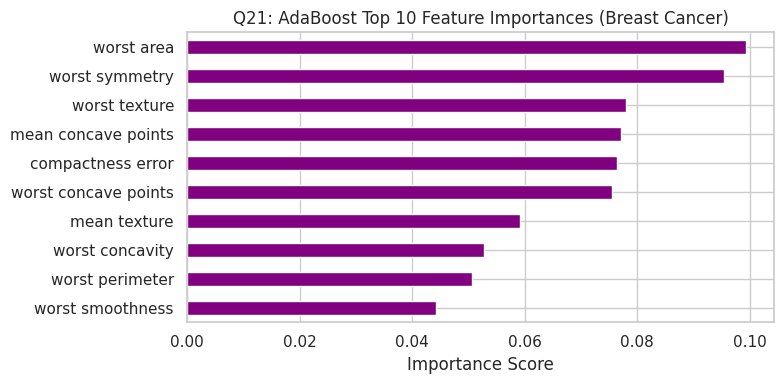

In [12]:
ada_cancer = AdaBoostClassifier(n_estimators=100, random_state=42).fit(Xc_tr, yc_tr)
ada_imp = pd.Series(ada_cancer.feature_importances_, index=cancer.feature_names).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 4))
ada_imp.plot(kind='barh', color='purple')
plt.gca().invert_yaxis()
plt.title("Q21: AdaBoost Top 10 Feature Importances (Breast Cancer)")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()


### 22. Train a Gradient Boosting Regressor and plot learning curves. [cite: 22, 25]


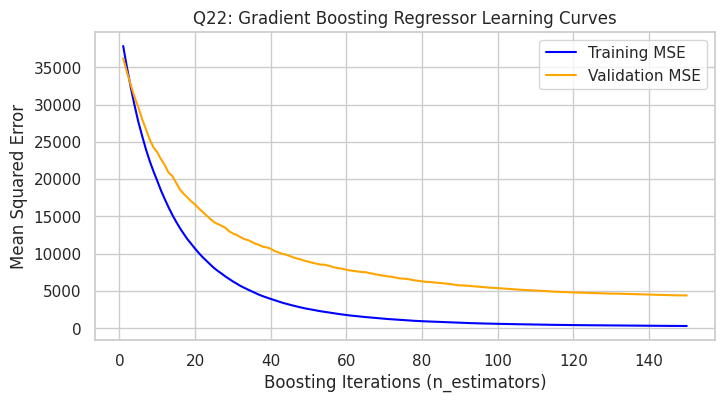

In [13]:
gbr_lc = GradientBoostingRegressor(n_estimators=150, random_state=42)
gbr_lc.fit(Xr_tr, yr_tr)

train_deviance = np.empty(gbr_lc.n_estimators_)
test_deviance = np.empty(gbr_lc.n_estimators_)

for i, y_pred in enumerate(gbr_lc.staged_predict(Xr_te)):
    test_deviance[i] = mean_squared_error(yr_te, y_pred)
for i, y_pred in enumerate(gbr_lc.staged_predict(Xr_tr)):
    train_deviance[i] = mean_squared_error(yr_tr, y_pred)

plt.figure(figsize=(8, 4))
plt.plot(range(1, gbr_lc.n_estimators_ + 1), train_deviance, label='Training MSE', color='blue')
plt.plot(range(1, gbr_lc.n_estimators_ + 1), test_deviance, label='Validation MSE', color='orange')
plt.title("Q22: Gradient Boosting Regressor Learning Curves")
plt.xlabel("Boosting Iterations (n_estimators)")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.show()


### 23. Train an XGBoost Classifier and visualize feature importance. [cite: 25]


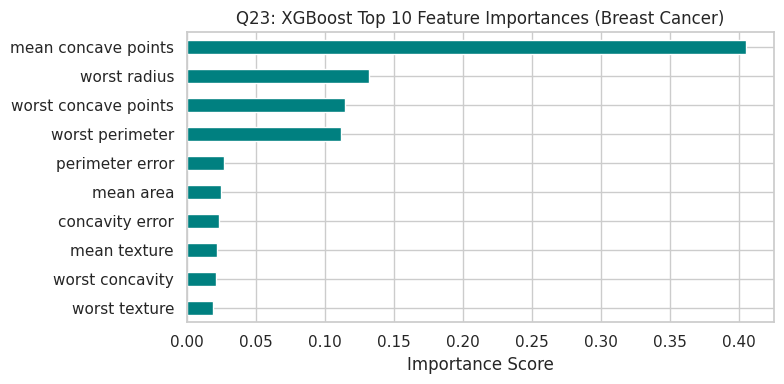

In [14]:
xgb_cancer = XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss').fit(Xc_tr, yc_tr)
xgb_imp = pd.Series(xgb_cancer.feature_importances_, index=cancer.feature_names).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 4))
xgb_imp.plot(kind='barh', color='teal')
plt.gca().invert_yaxis()
plt.title("Q23: XGBoost Top 10 Feature Importances (Breast Cancer)")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()


### 24. Train a CatBoost Classifier and plot the confusion matrix. [cite: 25]


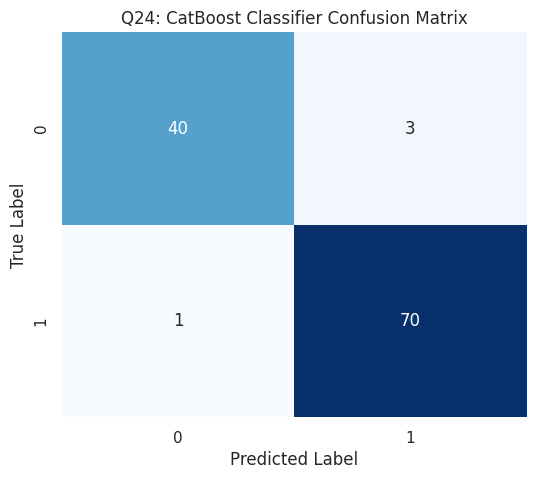

In [15]:
cat_cancer = CatBoostClassifier(iterations=100, verbose=0, random_state=42).fit(Xc_tr, yc_tr)
cm = confusion_matrix(yc_te, cat_cancer.predict(Xc_te))

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Q24: CatBoost Classifier Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()


### 25. Train an AdaBoost Classifier with different numbers of estimators and compare accuracy. [cite: 25]


In [16]:
print("Q25 - AdaBoost Accuracy across different n_estimators:")
for n in [10, 30, 50, 100, 200]:
    ada = AdaBoostClassifier(n_estimators=n, random_state=42).fit(X_tr, y_tr)
    acc = accuracy_score(y_te, ada.predict(X_te))
    print(f"  n_estimators = {n:3d} -> Accuracy: {acc:.4f}")


Q25 - AdaBoost Accuracy across different n_estimators:
  n_estimators =  10 -> Accuracy: 0.9125
  n_estimators =  30 -> Accuracy: 0.9125
  n_estimators =  50 -> Accuracy: 0.9125
  n_estimators = 100 -> Accuracy: 0.9313
  n_estimators = 200 -> Accuracy: 0.9313


### 26. Train a Gradient Boosting Classifier and visualize the ROC curve. [cite: 25]


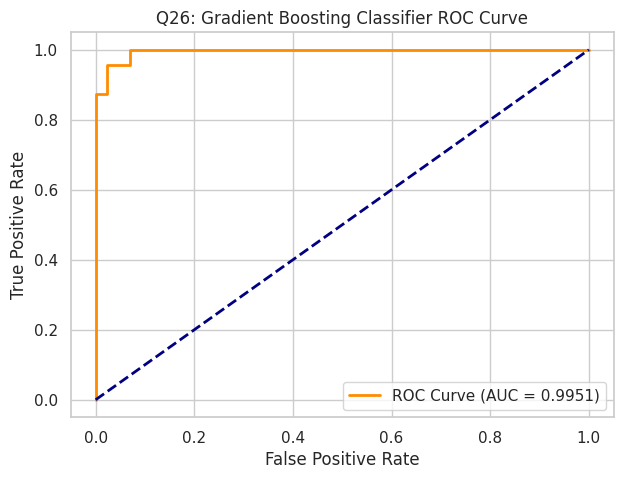

In [17]:
gbc_bin = GradientBoostingClassifier(random_state=42).fit(Xc_tr, yc_tr)
y_probs = gbc_bin.predict_proba(Xc_te)[:, 1]
fpr, tpr, _ = roc_curve(yc_te, y_probs)
auc_val = roc_auc_score(yc_te, y_probs)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {auc_val:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.title("Q26: Gradient Boosting Classifier ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.show()


### 27. Train an XGBoost Regressor and tune the learning rate using GridSearchCV. [cite: 25]


In [18]:
param_grid = {'learning_rate': [0.01, 0.05, 0.1, 0.2]}
grid_xgb = GridSearchCV(XGBRegressor(n_estimators=50, random_state=42), param_grid, cv=3, scoring='neg_mean_squared_error')
grid_xgb.fit(Xr_tr, yr_tr)

print(f"Q27 - Best Learning Rate: {grid_xgb.best_params_}")
print(f"Q27 - Best CV MSE:        {-grid_xgb.best_score_:.4f}")


Q27 - Best Learning Rate: {'learning_rate': 0.2}
Q27 - Best CV MSE:        9939.8816


### 28. Train a CatBoost Classifier on an imbalanced dataset and compare performance with class weighting. [cite: 28]


In [19]:
X_imb, y_imb = make_classification(n_samples=1000, weights=[0.9, 0.1], random_state=42)
Ximb_tr, Ximb_te, yimb_tr, yimb_te = train_test_split(X_imb, y_imb, test_size=0.2, random_state=42)

cat_std = CatBoostClassifier(iterations=100, verbose=0, random_state=42).fit(Ximb_tr, yimb_tr)
# Compute class weights manually for CatBoost
from sklearn.utils.class_weight import compute_class_weight
weights = compute_class_weight('balanced', classes=np.unique(yimb_tr), y=yimb_tr)
cat_weighted = CatBoostClassifier(iterations=100, class_weights=weights, verbose=0, random_state=42).fit(Ximb_tr, yimb_tr)

print(f"Q28 - Standard CatBoost F1-Score:  {f1_score(yimb_te, cat_std.predict(Ximb_te), zero_division=0):.4f}")
print(f"Q28 - Weighted CatBoost F1-Score: {f1_score(yimb_te, cat_weighted.predict(Ximb_te), zero_division=0):.4f}")


Q28 - Standard CatBoost F1-Score:  0.6207
Q28 - Weighted CatBoost F1-Score: 0.7027


### 29. Train an AdaBoost Classifier and analyze the effect of different learning rates. [cite: 25]


In [20]:
print("Q29 - AdaBoost Accuracy across different learning rates:")
for lr in [0.01, 0.1, 0.5, 1.0, 1.5]:
    ada_lr = AdaBoostClassifier(learning_rate=lr, n_estimators=50, random_state=42).fit(X_tr, y_tr)
    acc = accuracy_score(y_te, ada_lr.predict(X_te))
    print(f"  learning_rate = {lr:4.2f} -> Accuracy: {acc:.4f}")


Q29 - AdaBoost Accuracy across different learning rates:
  learning_rate = 0.01 -> Accuracy: 0.9250
  learning_rate = 0.10 -> Accuracy: 0.9187
  learning_rate = 0.50 -> Accuracy: 0.9062
  learning_rate = 1.00 -> Accuracy: 0.9125
  learning_rate = 1.50 -> Accuracy: 0.9062


### 30. Train an XGBoost Classifier for multi-class classification and evaluate using log-loss. [cite: 25]


In [21]:
iris = load_iris()
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(iris.data, iris.target, test_size=0.2, random_state=42)

xgb_multi = XGBClassifier(n_estimators=50, objective='multi:softprob', random_state=42, eval_metric='mlogloss')
xgb_multi.fit(Xi_tr, yi_tr)
probs = xgb_multi.predict_proba(Xi_te)

print(f"Q30 - Multi-class XGBoost Log Loss: {log_loss(yi_te, probs):.4f}")


Q30 - Multi-class XGBoost Log Loss: 0.0114
